# 11. Figure 4, tunable

The four-quadrant plot of the 38 topics, rebuilt on the current pipeline. The estimator
is the one the 2026 notebook `Four_Quadrant_TVR_OSI.ipynb` used, so the figure is the
same construction on new data rather than a new construction.

* **TVR** is `log(mean online share / mean NDC share)`, the ratio of the two cross-country
  means, not the mean of the country-level log ratios. The two differ, and this is the one
  that produced the published figure.
* **OSI** is the topic-level stance, each post's stance weighted by its recall on the
  topic, averaged over the 100 countries.
* Topic and group names come from `assets/figure_labels.json`, the same file Figure 1
  reads, so the labels match Table 1. The published version used older wording.

In [ ]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))  # the modules the notebooks import live in src/


In [12]:
import os, sys, json, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '.')
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import config as cfg, aggregate as ag, regress as rg, figures as fg

In [13]:
O = cfg.OUTPUT_DIR
OUT = 'output/figures'
os.makedirs(OUT, exist_ok=True)

posts = pd.read_parquet(os.path.join(O, 'climate_posts_2022.parquet'),
                        columns=['tweet_id', 'country'])
recall = pd.read_parquet(os.path.join(O, 'topic_recall_2022.parquet'))
ga_chunks = pd.read_csv(os.path.join(O, 'GA_topics.csv'), low_memory=False)
idx = pd.read_csv(os.path.join(O, 'indices_2022_by_country.csv'), index_col=0)

posts = ag.add_party(posts)
ga_country = rg.ga_by_country(ag.ndc_by_party(ga_chunks)).set_index('party')

# PP, the online share of each topic, summed over a country's posts then normalised
pp = recall[cfg.tw_columns()].groupby(posts.shp_country.to_numpy()).sum()
pp = pp.div(pp.sum(axis=1), axis=0)
# GA, the NDC share, normalised the same way
_sub = cfg.ndc_columns()
ga = ga_country[_sub].div(ga_country[_sub].sum(axis=1), axis=0)

COUNTRIES = [c for c in idx.index if c in pp.index and c in ga.index]

TOPIC_NAMES = fg.TOPIC_LABELS            # assets/figure_labels.json, matches Table 1
GROUP_NAMES = fg.GROUP_LABELS
TOPIC_TO_GROUP = {t: g for g, ids in cfg.TOPIC_GROUPS_TW.items() for t in ids}

rows = []
for t in range(1, 39):
    j = cfg.tw_topic_to_bertopic_index(t)
    rows.append({
        'topic': t,
        'name': TOPIC_NAMES[f'T{t}'],
        'group': TOPIC_TO_GROUP[t],
        'pp': pp.loc[COUNTRIES, f'Topic_{t}'].mean(),
        'ga': ga.loc[COUNTRIES, f'Subtopic_{j}'].mean(),
        'osi': idx.loc[COUNTRIES, f'T{t}_OSI'].replace([np.inf, -np.inf], np.nan).mean(),
    })
topics = pd.DataFrame(rows).set_index('topic')
topics['tvr'] = np.log(topics.pp.clip(lower=1e-8) / topics.ga.clip(lower=1e-8))

print(f'{len(COUNTRIES)} countries, 38 topics')
print(f'TVR {topics.tvr.min():+.2f} to {topics.tvr.max():+.2f}')
print(f'OSI {topics.osi.min():.3f} to {topics.osi.max():.3f}, mean {topics.osi.mean():.3f}')

100 countries, 38 topics
TVR -4.75 to +2.61
OSI 0.744 to 0.962, mean 0.858


## Settings

In [14]:
# ---- the points -----------------------------------------------------------------------
GROUP_COLORS = {'G1': '#AB3C64', 'G2': '#D796AC', 'G3': '#62AAB1',
                'G4': '#B4AFAA', 'G5': '#A6C0C1', 'G6': '#B1ABD1'}
DOT_SIZE  = 520
DOT_EDGE  = 'white'
DOT_LW    = 1.8
DOT_ALPHA = 0.88
NUM_SIZE  = 10                 # the numeral inside the circle
NUM_COLOR = 'white'

# ---- where the quadrants are split ------------------------------------------------------
TVR_CUT = 0.0
OSI_CUT = None                 # None uses the mean OSI over the 38 topics
GRID_COLOR, GRID_LW, GRID_LS, GRID_ALPHA = '#888888', 1.2, '--', 0.6

# The published figure leaves the quadrants unshaded. True brings back the tinted version.
SHADE = False
SHADE_COLORS = {'I': '#2A9D8F', 'II': '#E9C46A', 'III': '#457B9D', 'IV': '#E63946'}
SHADE_ALPHA  = 0.05

# ---- numbers pulled off their circle ----------------------------------------------------
# topic: (dx, dy) in data units. Use it where two circles overlap. The circle stays put,
# only the numeral moves, joined by a thin leader.
# Same magnitude for all three, so the leaders sit at one angle and only the
# direction changes.
MANUAL_OFFSETS = {11: (-0.42, +0.012),
                  13: (+0.42, +0.012),
                  34: (+0.42, -0.012)}
LEADER_COLOR, LEADER_LW = '#999999', 0.8
OFFSET_NUM_COLOR = '#333333'
CROWD_REPORT = True            # print which circles are close enough to overlap

# ---- corner labels ----------------------------------------------------------------------
QUAD_TEXT = {'I': 'I: Amplified support', 'II': 'II: Amplified dissent',
             'III': 'III: Silent support', 'IV': 'IV: Silent dissent'}
QUAD_SIZE, QUAD_COLOR, QUAD_ALPHA, QUAD_ITALIC = 14, '#555555', 0.85, True

# ---- axes --------------------------------------------------------------------------------
XLABEL = ('Topic Visibility Ratio (TVR)\n'
          '\u2190 Under-discussed online    Over-discussed online \u2192')
YLABEL = ('Online Stance Index (OSI)\n'
          '\u2190 More critical/neutral    More supportive \u2192')
AXIS_SIZE, TICK_SIZE = 12, 10
PAD_X, PAD_Y = 0.25, 0.03

# ---- the legend panel ---------------------------------------------------------------------
LEGEND_TITLE = 'Topic Groups'
LEGEND_TITLE_SIZE = 14
GRP_SIZE, GRP_DOT = 10.5, 130
TOPIC_SIZE, TOPIC_DOT, TOPIC_NUM_SIZE = 8.5, 150, 8
LINE_H = 0.0215
SHOW_QUADRANT_TAG = True       # the [I] .. [IV] after each topic name
SHOW_THRESHOLD_NOTE = True

# ---- layout ---------------------------------------------------------------------------------
FONT = None                    # None keeps matplotlib's default, which the published figure uses
FIGSIZE, WIDTH_RATIOS, DPI = (20, 12), [3, 2], 300
SUPTITLE = None                # the caption carries the title, so the figure has none

## The figure

In [15]:
def quadrant(tvr, osi, cut):
    if tvr > TVR_CUT:
        return 'I' if osi > cut else 'II'
    return 'III' if osi > cut else 'IV'


def crowded(d, xlim, ylim, tol=0.035):
    """Pairs whose circles are close enough in display space to overlap."""
    x = (d.tvr - xlim[0]) / (xlim[1] - xlim[0])
    y = (d.osi - ylim[0]) / (ylim[1] - ylim[0])
    out = []
    for a in d.index:
        for b in d.index:
            if a < b and np.hypot((x[a] - x[b]) * WIDTH_RATIOS[0] / 5, y[a] - y[b]) < tol:
                out.append((a, b))
    return out


def draw(d=None):
    d = topics if d is None else d
    cut = d.osi.mean() if OSI_CUT is None else OSI_CUT
    if FONT:
        mpl.rcParams['font.family'] = FONT

    fig = plt.figure(figsize=FIGSIZE, dpi=110)
    gs = fig.add_gridspec(1, 2, width_ratios=WIDTH_RATIOS, wspace=0.05)
    ax, ax_leg = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    xlim = (d.tvr.min() - PAD_X, d.tvr.max() + PAD_X)
    ylim = (d.osi.min() - PAD_Y, d.osi.max() + PAD_Y)

    if SHADE:
        for q, (xs, ys) in {'I': ((TVR_CUT, xlim[1]), (cut, ylim[1])),
                            'II': ((TVR_CUT, xlim[1]), (ylim[0], cut)),
                            'III': ((xlim[0], TVR_CUT), (cut, ylim[1])),
                            'IV': ((xlim[0], TVR_CUT), (ylim[0], cut))}.items():
            ax.fill_between(xs, ys[0], ys[1], color=SHADE_COLORS[q],
                            alpha=SHADE_ALPHA, zorder=0)

    ax.axvline(TVR_CUT, color=GRID_COLOR, lw=GRID_LW, ls=GRID_LS, alpha=GRID_ALPHA, zorder=1)
    ax.axhline(cut, color=GRID_COLOR, lw=GRID_LW, ls=GRID_LS, alpha=GRID_ALPHA, zorder=1)

    for t, r in d.iterrows():
        c = GROUP_COLORS[r.group]
        ax.scatter(r.tvr, r.osi, s=DOT_SIZE, c=c, edgecolors=DOT_EDGE,
                   linewidths=DOT_LW, alpha=DOT_ALPHA, zorder=3)
        if t in MANUAL_OFFSETS:
            dx, dy = MANUAL_OFFSETS[t]
            ax.annotate(str(t), xy=(r.tvr, r.osi), xytext=(r.tvr + dx, r.osi + dy),
                        ha='center', va='center', fontsize=NUM_SIZE, fontweight='bold',
                        color=OFFSET_NUM_COLOR, zorder=5,
                        arrowprops=dict(arrowstyle='-', color=LEADER_COLOR,
                                        lw=LEADER_LW, shrinkA=0, shrinkB=12))
        else:
            ax.text(r.tvr, r.osi, str(t), ha='center', va='center', fontsize=NUM_SIZE,
                    fontweight='bold', color=NUM_COLOR, zorder=4,
                    path_effects=[pe.withStroke(linewidth=0.3, foreground='#333333')])

    lp = dict(fontsize=QUAD_SIZE, color=QUAD_COLOR, alpha=QUAD_ALPHA,
              fontstyle='italic' if QUAD_ITALIC else 'normal')
    ax.text(xlim[1] - 0.08, ylim[1] - 0.005, QUAD_TEXT['I'], ha='right', va='top', **lp)
    ax.text(xlim[1] - 0.08, ylim[0] + 0.005, QUAD_TEXT['II'], ha='right', va='bottom', **lp)
    ax.text(xlim[0] + 0.08, ylim[1] - 0.005, QUAD_TEXT['III'], ha='left', va='top', **lp)
    ax.text(xlim[0] + 0.08, ylim[0] + 0.005, QUAD_TEXT['IV'], ha='left', va='bottom', **lp)

    ax.set_xlabel(XLABEL, fontsize=AXIS_SIZE, labelpad=10)
    ax.set_ylabel(YLABEL, fontsize=AXIS_SIZE, labelpad=10)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    # ---- the legend panel
    ax_leg.axis('off')
    ax_leg.text(0.02, 0.97, LEGEND_TITLE, fontsize=LEGEND_TITLE_SIZE, fontweight='bold',
                va='top', transform=ax_leg.transAxes)
    y = 0.93
    for g in [f'G{i}' for i in range(1, 7)]:
        c = GROUP_COLORS[g]
        ax_leg.scatter([0.02], [y], s=GRP_DOT, c=c, edgecolors='white', linewidths=1,
                       transform=ax_leg.transAxes, zorder=3, clip_on=False)
        ax_leg.text(0.06, y, f'{g}: {GROUP_NAMES[g]}', fontsize=GRP_SIZE, fontweight='bold',
                    va='center', color=c, transform=ax_leg.transAxes)
        y -= LINE_H * 1.4
        for t in sorted(cfg.TOPIC_GROUPS_TW[g]):
            r = d.loc[t]
            tag = f"  [{quadrant(r.tvr, r.osi, cut)}]" if SHOW_QUADRANT_TAG else ''
            ax_leg.scatter([0.04], [y], s=TOPIC_DOT, c=c, edgecolors='white', linewidths=0.8,
                           transform=ax_leg.transAxes, zorder=3, clip_on=False)
            ax_leg.text(0.04, y, str(t), ha='center', va='center', fontsize=TOPIC_NUM_SIZE,
                        fontweight='bold', color='white', transform=ax_leg.transAxes, zorder=4,
                        path_effects=[pe.withStroke(linewidth=0.2, foreground='#333')])
            ax_leg.text(0.07, y, f'{r["name"]}{tag}', fontsize=TOPIC_SIZE, va='center',
                        color='#333333', transform=ax_leg.transAxes)
            y -= LINE_H
        y -= LINE_H * 0.4

    if SHOW_THRESHOLD_NOTE:
        ax_leg.text(0.02, y - 0.01, f'\u2500\u2500 OSI threshold = {cut:.2f} (mean over the 38 topics)',
                    fontsize=9, color='#888888', va='top', transform=ax_leg.transAxes)
        ax_leg.text(0.02, y - 0.035, f'\u2500\u2500 TVR = {TVR_CUT:g} (equal NDC and online attention)',
                    fontsize=9, color='#888888', va='top', transform=ax_leg.transAxes)
    if SUPTITLE:
        fig.suptitle(SUPTITLE, fontsize=15, fontweight='bold', y=0.99)

    if CROWD_REPORT:
        pairs = crowded(d, xlim, ylim)
        print('circles close enough to overlap:',
              pairs or 'none', '  (set MANUAL_OFFSETS for these)')
    return fig, cut

circles close enough to overlap: [(3, 12), (3, 18), (8, 30), (10, 11), (10, 33), (11, 33), (13, 36), (14, 36), (16, 24), (17, 21), (21, 24), (34, 38)]   (set MANUAL_OFFSETS for these)
saved output/figures/Figure4_quadrants.png


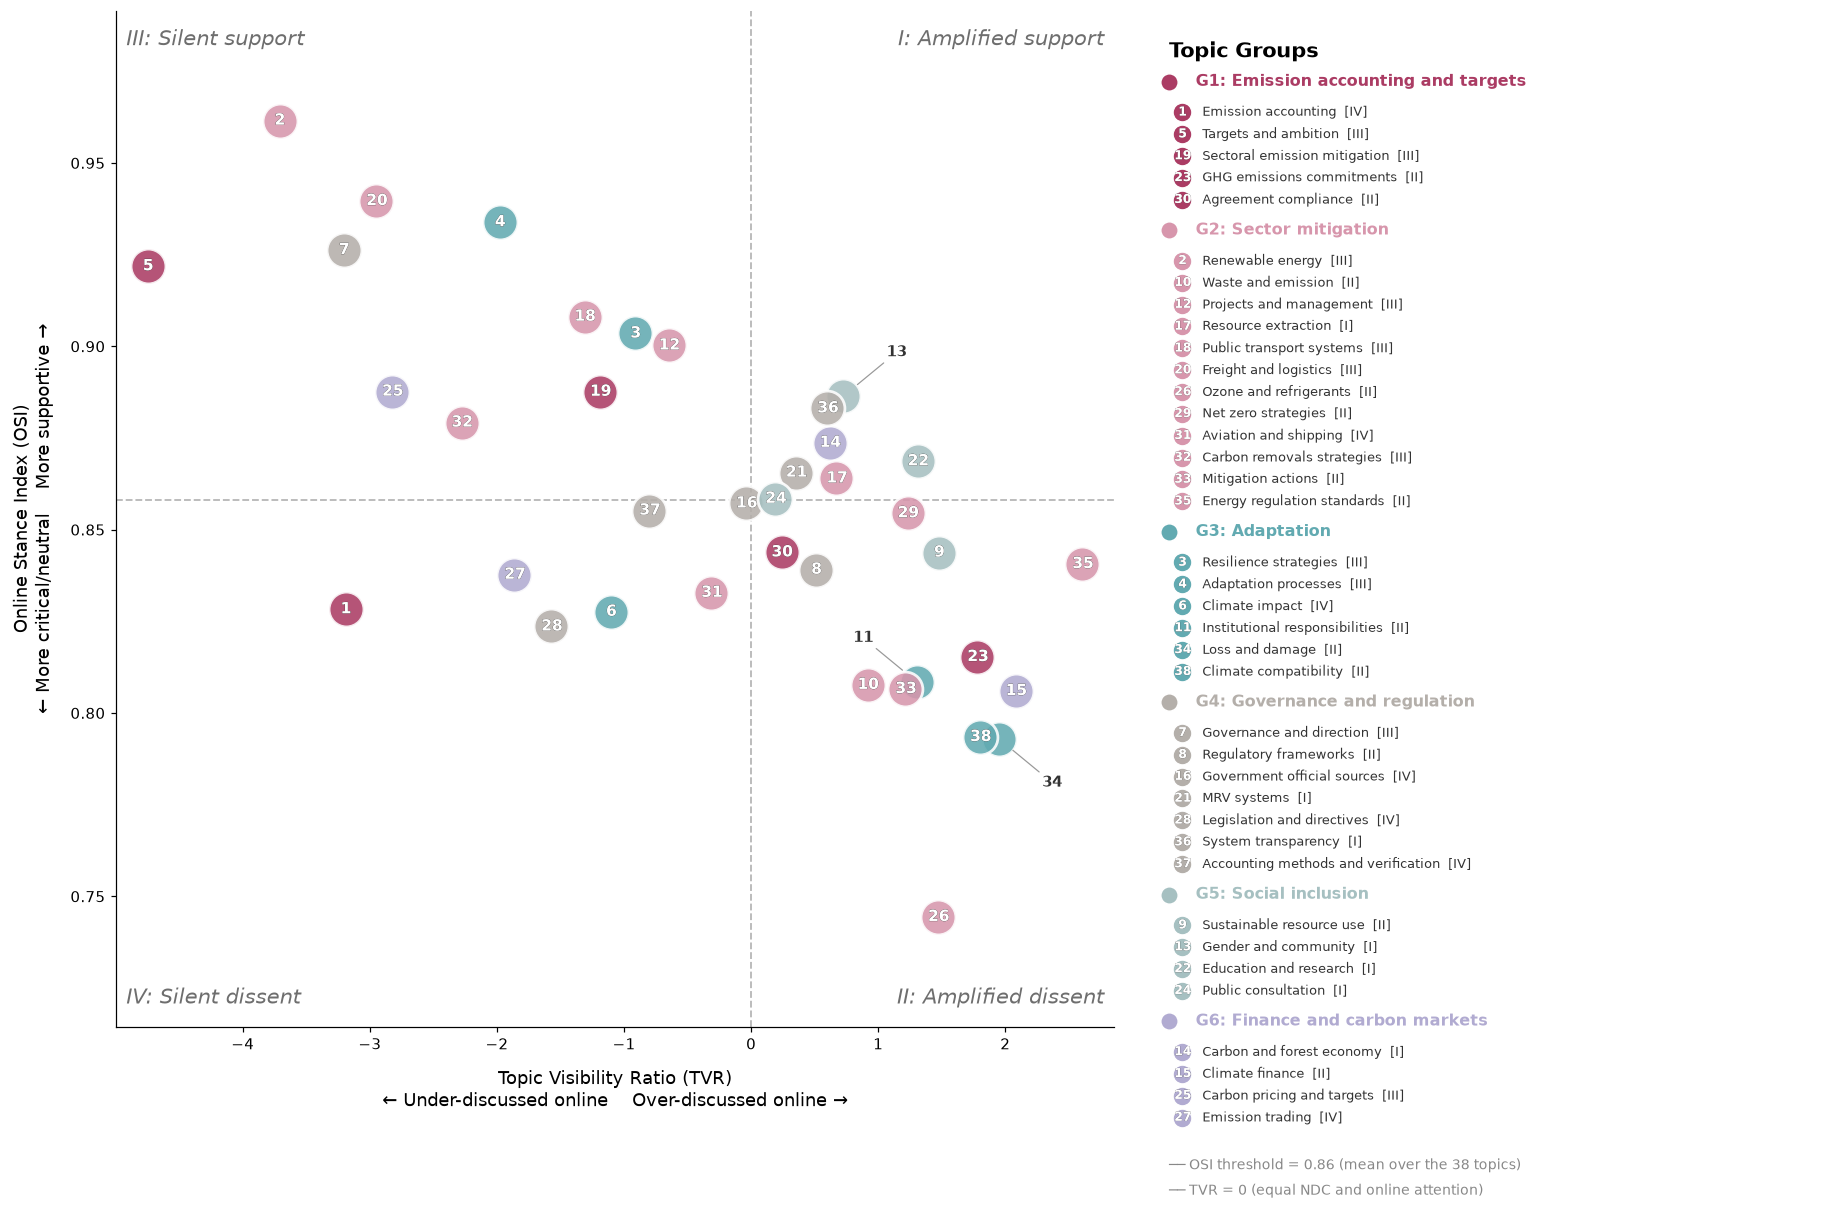

In [16]:
fig, CUT = draw()
for ext in ('png', 'pdf'):
    fig.savefig(f'{OUT}/Figure4_quadrants.{ext}', dpi=DPI, bbox_inches='tight',
                facecolor='white')
print('saved', f'{OUT}/Figure4_quadrants.png')
plt.show()

## The quadrant table

In [ ]:
out = topics[['name', 'group', 'tvr', 'osi']].copy()
out.insert(0, 'topic_id', [f'T{t}' for t in out.index])
out['group_name'] = out.group.map(GROUP_NAMES)
out['quadrant'] = [quadrant(r.tvr, r.osi, CUT) for _, r in out.iterrows()]
out['quadrant_name'] = out.quadrant.map({'I': 'Amplified support', 'II': 'Amplified dissent',
                                         'III': 'Silent support', 'IV': 'Silent dissent'})
out = out[['topic_id', 'name', 'group', 'group_name', 'tvr', 'osi',
           'quadrant', 'quadrant_name']].round({'tvr': 3, 'osi': 3})
out.to_csv('output/SI/Figure4_source_data.csv', index=False)
print(out.quadrant.value_counts().reindex(['I', 'II', 'III', 'IV']).to_string())
print('\nwrote output/SI/Figure4_source_data.csv')
out.sort_values(['quadrant', 'tvr'])